In [ ]:
!pip install -q qiskit qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 90.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 97.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 109.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 5.8 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf

from skimage.metrics import (
    mean_squared_error as mse,
    peak_signal_noise_ratio as psnr,
    structural_similarity as ssim,
)

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

import qiskit

print("Qiskit version:", qiskit.__version__)

Qiskit version: 2.5.2


In [ ]:
# Load MNIST
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Same test image used in conventional FRQI
original = X_test[0]
label = y_test[0]

# Resize to 16×16
image = cv2.resize(
    original,
    (16, 16),
    interpolation=cv2.INTER_AREA
)

print("Image shape:", image.shape)
print("Digit:", label)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Image shape: (16, 16)
Digit: 7


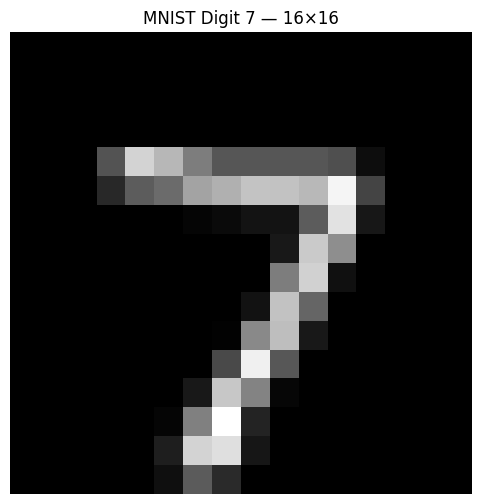

In [ ]:
plt.figure(figsize=(6, 6))

plt.imshow(
    image,
    cmap="gray"
)

plt.title(f"MNIST Digit {label} — 16×16")
plt.axis("off")

plt.show()

In [ ]:
def adaptive_error_partition(
    image,
    min_size=2,
    max_size=8,
    mse_threshold=500
):
    image_float = image.astype(np.float32)

    adaptive_patches = []

    def process_region(x, y, size):

        patch = image_float[
            y:y+size,
            x:x+size
        ]

        mean_intensity = np.mean(patch)

        reconstructed_patch = np.full(
            patch.shape,
            mean_intensity,
            dtype=np.float32
        )

        mse = np.mean(
            (patch - reconstructed_patch) ** 2
        )

        if (
            mse > mse_threshold
            and size > min_size
        ):

            new_size = size // 2

            process_region(
                x,
                y,
                new_size
            )

            process_region(
                x + new_size,
                y,
                new_size
            )

            process_region(
                x,
                y + new_size,
                new_size
            )

            process_region(
                x + new_size,
                y + new_size,
                new_size
            )

        else:

            adaptive_patches.append({
                "x": x,
                "y": y,
                "size": size,
                "intensity": mean_intensity,
                "mse": mse
            })

    for y in range(0, 16, max_size):

        for x in range(0, 16, max_size):

            process_region(
                x,
                y,
                max_size
            )

    return adaptive_patches

In [ ]:
image_16 = cv2.resize(
    X_test[0],
    (16, 16),
    interpolation=cv2.INTER_AREA
)

adaptive_patches = adaptive_error_partition(
    image_16,
    min_size=2,
    max_size=8,
    mse_threshold=500
)

print("Total patches:", len(adaptive_patches))

from collections import Counter

patch_distribution = Counter(
    patch["size"]
    for patch in adaptive_patches
)

print("Patch distribution:", patch_distribution)

Total patches: 31
Patch distribution: Counter({2: 20, 4: 11})


In [ ]:
classical_error_reconstructed = np.zeros(
    (16, 16),
    dtype=np.float64
)

for patch in adaptive_patches:

    x = patch["x"]
    y = patch["y"]
    size = patch["size"]

    intensity = patch["intensity"]

    classical_error_reconstructed[
        y:y+size,
        x:x+size
    ] = intensity

mse_error = mse(
    image_16,
    classical_error_reconstructed
)

psnr_error = psnr(
    image_16,
    classical_error_reconstructed,
    data_range=255
)

ssim_error = ssim(
    image_16,
    classical_error_reconstructed,
    data_range=255
)

print("Error-Based Adaptive Reconstruction")
print("MSE  :", mse_error)
print("PSNR :", psnr_error, "dB")
print("SSIM :", ssim_error)

Error-Based Adaptive Reconstruction
MSE  : 785.186279296875
PSNR : 19.1810765893347 dB
SSIM : 0.8292778700110641


In [ ]:
mse_thresholds = [
    100,
    250,
    500,
    750,
    1000,
    1500
]

error_threshold_results = []

for mse_threshold in mse_thresholds:

    total_patches = 0
    total_mse = 0
    total_psnr = 0
    total_ssim = 0

    for idx in range(100):

        image_16 = cv2.resize(
            X_test[idx],
            (16, 16),
            interpolation=cv2.INTER_AREA
        )

        adaptive_patches = adaptive_error_partition(
            image_16,
            min_size=2,
            max_size=8,
            mse_threshold=mse_threshold
        )

        reconstructed = np.zeros(
            (16, 16),
            dtype=np.float64
        )

        for patch in adaptive_patches:

            x = patch["x"]
            y = patch["y"]
            size = patch["size"]

            reconstructed[
                y:y+size,
                x:x+size
            ] = patch["intensity"]

        total_patches += len(adaptive_patches)

        total_mse += mse(
            image_16,
            reconstructed
        )

        total_psnr += psnr(
            image_16,
            reconstructed,
            data_range=255
        )

        total_ssim += ssim(
            image_16,
            reconstructed,
            data_range=255
        )

    error_threshold_results.append({

        "MSE Threshold": mse_threshold,
        "Average Patches": total_patches / 100,
        "Average MSE": total_mse / 100,
        "Average PSNR": total_psnr / 100,
        "Average SSIM": total_ssim / 100
    })

error_threshold_results = pd.DataFrame(
    error_threshold_results
)

error_threshold_results = error_threshold_results.round(3)

display(error_threshold_results)

,MSE Threshold,Average Patches,Average MSE,Average PSNR,Average SSIM
0,100,40.60,1213.060,17.492,0.769
1,250,39.31,1214.684,17.485,0.769
2,500,38.32,1217.012,17.476,0.768
3,750,37.66,1220.172,17.463,0.768
4,1000,36.43,1232.520,17.409,0.763
5,1500,34.78,1257.917,17.298,0.751


In [ ]:
adaptive_patches = adaptive_error_partition(
    image,
    min_size=2,
    max_size=8,
    mse_threshold=500
)

print("Improved Adaptive Error-Based Patching")
print("---------------------------------------")

print(
    "Total patches:",
    len(adaptive_patches)
)

Improved Adaptive Error-Based Patching
---------------------------------------
Total patches: 31


In [ ]:
from collections import Counter

patch_distribution = Counter(
    p["size"]
    for p in adaptive_patches
)

print("Patch distribution")
print("------------------")

for size in [8, 4, 2]:

    print(
        f"{size}×{size} patches:",
        patch_distribution.get(size, 0)
    )

Patch distribution
------------------
8×8 patches: 0
4×4 patches: 11
2×2 patches: 20


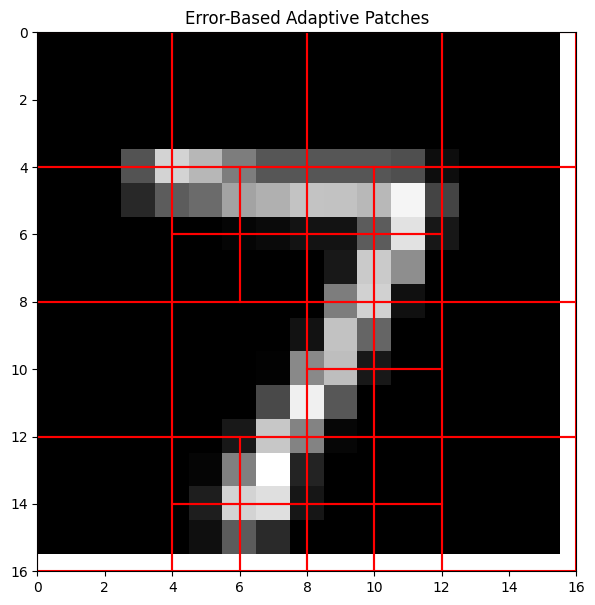

In [ ]:
import matplotlib.patches as mpl_patches

fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(
    image,
    cmap="gray"
)

for p in adaptive_patches:

    rect = mpl_patches.Rectangle(
        (p["x"], p["y"]),
        p["size"],
        p["size"],
        linewidth=1.5,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

ax.set_title(
    "Error-Based Adaptive Patches"
)

ax.set_xlim(0, 16)
ax.set_ylim(16, 0)

plt.show()

In [ ]:
from collections import Counter

print("Adaptive Patch Error Analysis")
print("-----------------------------")

for size in [8, 4, 2]:

    patches = [
        p for p in adaptive_patches
        if p["size"] == size
    ]

    print(f"\n{size}×{size} patches:")
    print("Count:", len(patches))

    if len(patches) > 0:

        errors = [
            p["mse"]
            for p in patches
        ]

        print("Minimum MSE:", min(errors))
        print("Maximum MSE:", max(errors))
        print("Average MSE:", np.mean(errors))

Adaptive Patch Error Analysis
-----------------------------

8×8 patches:
Count: 0

4×4 patches:
Count: 11
Minimum MSE: 0.0
Maximum MSE: 462.10938
Average MSE: 95.2468

2×2 patches:
Count: 20
Minimum MSE: 0.0
Maximum MSE: 7242.75
Average MSE: 2303.0532


In [ ]:
print("Patch Information Loss Analysis")
print("--------------------------------")

for size in [4, 2]:

    patches = [
        p for p in adaptive_patches
        if p["size"] == size
    ]

    print(f"\n{size}×{size} patches")
    print("Count:", len(patches))

    if len(patches) > 0:

        mean_errors = [
            p["mse"]
            for p in patches
        ]

        print(
            "Average mean-representation MSE:",
            np.mean(mean_errors)
        )

        print(
            "Maximum mean-representation MSE:",
            np.max(mean_errors)
        )

Patch Information Loss Analysis
--------------------------------

4×4 patches
Count: 11
Average mean-representation MSE: 95.2468
Maximum mean-representation MSE: 462.10938

2×2 patches
Count: 20
Average mean-representation MSE: 2303.0532
Maximum mean-representation MSE: 7242.75


In [ ]:
adaptive_elements = []

for patch in adaptive_patches:

    x = patch["x"]
    y = patch["y"]
    size = patch["size"]

    intensity = patch["intensity"]

    adaptive_elements.append({

        "x": x,
        "y": y,
        "size": size,
        "intensity": intensity,
        "mse": patch["mse"]
    })

In [ ]:
for element in adaptive_elements:

    intensity = element["intensity"]

    element["theta"] = (
        intensity / 255.0
    ) * (np.pi / 2)

from collections import Counter

patch_distribution = Counter(
    element["size"]
    for element in adaptive_elements
)

num_patches = len(
    adaptive_elements
)

position_qubits_count = int(
    np.ceil(
        np.log2(num_patches)
    )
)

intensity_qubit = 0

total_qubits = (
    position_qubits_count + 1
)

print("Adaptive-FRQI Preparation")
print("--------------------------")

print("\nAdaptive patch distribution")

for size in [8, 4, 2]:

    print(
        f"{size}×{size} patches:",
        patch_distribution.get(size, 0)
    )

print(
    "\nTotal adaptive patches:",
    num_patches
)

print("\nQuantum resources")

print(
    "Position qubits:",
    position_qubits_count
)

print(
    "Intensity qubits:",
    1
)

print(
    "Total Adaptive-FRQI qubits:",
    total_qubits
)

print("\nFirst 10 adaptive quantum elements")

for i, element in enumerate(
    adaptive_elements[:10]
):

    print(
        f"Patch {i} | "
        f"Position=({element['x']},{element['y']}) | "
        f"Size={element['size']}×{element['size']} | "
        f"Intensity={element['intensity']:.2f} | "
        f"Theta={element['theta']:.4f}"
    )

Adaptive-FRQI Preparation
--------------------------

Adaptive patch distribution
8×8 patches: 0
4×4 patches: 11
2×2 patches: 20

Total adaptive patches: 31

Quantum resources
Position qubits: 5
Intensity qubits: 1
Total Adaptive-FRQI qubits: 6

First 10 adaptive quantum elements
Patch 0 | Position=(0,0) | Size=4×4 | Intensity=0.00 | Theta=0.0000
Patch 1 | Position=(4,0) | Size=4×4 | Intensity=0.00 | Theta=0.0000
Patch 2 | Position=(0,4) | Size=4×4 | Intensity=7.62 | Theta=0.0470
Patch 3 | Position=(4,4) | Size=2×2 | Intensity=146.50 | Theta=0.9024
Patch 4 | Position=(6,4) | Size=2×2 | Intensity=136.00 | Theta=0.8378
Patch 5 | Position=(4,6) | Size=2×2 | Intensity=0.00 | Theta=0.0000
Patch 6 | Position=(6,6) | Size=2×2 | Intensity=3.75 | Theta=0.0231
Patch 7 | Position=(8,0) | Size=4×4 | Intensity=0.00 | Theta=0.0000
Patch 8 | Position=(12,0) | Size=4×4 | Intensity=0.00 | Theta=0.0000
Patch 9 | Position=(8,4) | Size=2×2 | Intensity=138.50 | Theta=0.8532


In [ ]:
from qiskit import QuantumCircuit

num_patches = len(
    adaptive_elements
)

position_qubits_count = int(
    np.ceil(
        np.log2(num_patches)
    )
)

intensity_qubit = 0

position_qubits = list(
    range(
        1,
        position_qubits_count + 1
    )
)

total_qubits = (
    position_qubits_count + 1
)

adaptive_qc = QuantumCircuit(
    total_qubits
)

for q in position_qubits:

    adaptive_qc.h(q)


def apply_adaptive_frqi_rotation(
    qc,
    position_qubits,
    intensity_qubit,
    patch_index,
    angle
):

    binary = format(
        patch_index,
        f"0{len(position_qubits)}b"
    )

    binary = binary[::-1]

    for q, bit in zip(
        position_qubits,
        binary
    ):

        if bit == "0":

            qc.x(q)

    qc.mcry(
        2 * angle,
        position_qubits,
        intensity_qubit
    )

    for q, bit in zip(
        position_qubits,
        binary
    ):

        if bit == "0":

            qc.x(q)


for patch_index, element in enumerate(
    adaptive_elements
):

    apply_adaptive_frqi_rotation(
        adaptive_qc,
        position_qubits,
        intensity_qubit,
        patch_index,
        element["theta"]
    )

print(adaptive_qc)

     ┌───┐┌────────┐                                                    »
q_0: ┤ H ├┤ P(π/8) ├────────────────────────────────────────────────────»
     ├───┤└─┬───┬──┘┌────────┐                                          »
q_1: ┤ H ├──┤ X ├───┤ P(π/8) ├──■───────────────■────────────────────■──»
     ├───┤  ├───┤   ├────────┤┌─┴─┐┌─────────┐┌─┴─┐                  │  »
q_2: ┤ H ├──┤ X ├───┤ P(π/8) ├┤ X ├┤ P(-π/8) ├┤ X ├──■───────────────┼──»
     ├───┤  ├───┤   ├────────┤└───┘└─────────┘└───┘┌─┴─┐┌─────────┐┌─┴─┐»
q_3: ┤ H ├──┤ X ├───┤ P(π/8) ├─────────────────────┤ X ├┤ P(-π/8) ├┤ X ├»
     ├───┤  ├───┤   └────────┘                     └───┘└─────────┘└───┘»
q_4: ┤ H ├──┤ X ├───────────────────────────────────────────────────────»
     ├───┤  ├───┤                                                       »
q_5: ┤ H ├──┤ X ├───────────────────────────────────────────────────────»
     └───┘  └───┘                                                       »
«                                    ┌

In [ ]:
print("Adaptive-FRQI Resource Analysis")
print("--------------------------------")

print(
    "Number of adaptive patches:",
    len(adaptive_elements)
)

print(
    "Position qubits:",
    position_qubits_count
)

print(
    "Intensity qubits:",
    1
)

print(
    "Total qubits:",
    adaptive_qc.num_qubits
)

print(
    "Total gates:",
    adaptive_qc.size()
)

print(
    "Circuit depth:",
    adaptive_qc.depth()
)

Adaptive-FRQI Resource Analysis
--------------------------------
Number of adaptive patches: 31
Position qubits: 5
Intensity qubits: 1
Total qubits: 6
Total gates: 3141
Circuit depth: 1871


In [ ]:
print("Adaptive-FRQI gate counts")
print("-------------------------")

print(
    adaptive_qc.count_ops()
)

Adaptive-FRQI gate counts
-------------------------
OrderedDict({'cx': 1240, 'p': 930, 'h': 253, 't': 248, 'tdg': 186, 'x': 160, 'ry': 124})


In [ ]:
adaptive_qc.draw(
    "text",
    fold=120
)

┌───┐┌────────┐                                                                                   ┌───┐┌─────────┐»
q_0: ┤ H ├┤ P(π/8) ├───────────────────────────────────────────────────────────────────────────────────┤ X ├┤ P(-π/8) ├»
     ├───┤└─┬───┬──┘┌────────┐                                                                         └─┬─┘└─────────┘»
q_1: ┤ H ├──┤ X ├───┤ P(π/8) ├──■───────────────■────────────────────■──────────────────────────────■────┼─────────────»
     ├───┤  ├───┤   ├────────┤┌─┴─┐┌─────────┐┌─┴─┐                  │                              │    │             »
q_2: ┤ H ├──┤ X ├───┤ P(π/8) ├┤ X ├┤ P(-π/8) ├┤ X ├──■───────────────┼──────────────■───────────────┼────┼─────────────»
     ├───┤  ├───┤   ├────────┤└───┘└─────────┘└───┘┌─┴─┐┌─────────┐┌─┴─┐┌────────┐┌─┴─┐┌─────────┐┌─┴─┐  │             »
q_3: ┤ H ├──┤ X ├───┤ P(π/8) ├─────────────────────┤ X ├┤ P(-π/8) ├┤ X ├┤ P(π/8) ├┤ X ├┤ P(-π/8) ├┤ X ├──■─────────────»
     ├───┤  ├───┤   └────────┘                     └───┘└─────────┘└───┘└────────┘└───┘└─────────┘└───┘                »
q_4: ┤ H ├──┤ X ├──────────────────────────────────────────────────────────────────────────────────────────────────────»
     ├───┤  ├───┤                                                                                                      »
q_5: ┤ H ├──┤ X ├──────────────────────────────────────────────────────────────────────────────────────────────────────»
     └───┘  └───┘                                                                                                      »
«     ┌───┐┌────────┐┌───┐┌─────────┐┌───┐┌────────┐┌───┐┌─────────┐┌───┐┌────────┐┌───┐┌─────────┐┌───┐  ┌───┐   »
«q_0: ┤ X ├┤ P(π/8) ├┤ X ├┤ P(-π/8) ├┤ X ├┤ P(π/8) ├┤ X ├┤ P(-π/8) ├┤ X ├┤ P(π/8) ├┤ X ├┤ P(-π/8) ├┤ X ├──┤ H ├───»
«     └─┬─┘└────────┘└─┬─┘└─────────┘└─┬─┘└────────┘└─┬─┘└─────────┘└─┬─┘└────────┘└─┬─┘└─────────┘└─┬─┘┌─┴───┴──┐»
«q_1: ──┼──────────────┼───────────────■──────────────┼───────────────┼──────────────┼───────────────■──┤ P(π/8) ├»
«       │              │                              │               │  ┌────────┐  │                  └────────┘»
«q_2: ──■──────────────┼──────────────────────────────┼───────────────■──┤ P(π/8) ├──┼────────────────────────────»
«                      │                              │                  └────────┘  │   ┌────────┐               »
«q_3: ─────────────────■──────────────────────────────■──────────────────────────────■───┤ P(π/8) ├───────────────»
«                                                                                        └────────┘               »
«q_4: ────────────────────────────────────────────────────────────────────────────────────────────────────────────»
«                                                                                                                 »
«q_5: ────────────────────────────────────────────────────────────────────────────────────────────────────────────»
«                                                                                                                 »
«     ┌───────┐   ┌───┐   ┌───┐┌─────┐     ┌───┐   ┌───┐        ┌───┐ ┌─────┐       ┌───┐   ┌───┐    ┌───┐ ┌───────┐»
«q_0: ┤ Ry(0) ├───┤ H ├───┤ X ├┤ Tdg ├─────┤ X ├───┤ T ├────────┤ X ├─┤ Tdg ├───────┤ X ├───┤ T ├────┤ H ├─┤ Ry(0) ├»
«     └───────┘   └───┘   └─┬─┘└─────┘     └─┬─┘   └───┘        └─┬─┘ └─────┘       └─┬─┘   └───┘    └───┘ └───────┘»
«q_1: ────■─────────────────┼─────■──────────┼───────────────■────┼───────────────────┼────────────────■────────────»
«       ┌─┴─┐  ┌─────────┐  │   ┌─┴─┐        │               │    │                   │                │            »
«q_2: ──┤ X ├──┤ P(-π/8) ├──┼───┤ X ├───■────┼───────────────┼────┼──────────────■────┼────────────────┼────────────»
«       └───┘  └─────────┘  │   └───┘ ┌─┴─┐  │  ┌─────────┐┌─┴─┐  │  ┌────────┐┌─┴─┐  │  ┌─────────┐ ┌─┴─┐          »
«q_3: ──────────────────────┼─────────┤ X ├──┼──┤ P(-π/8) ├┤ X ├──┼──┤ P(π/8) ├┤ X ├──┼──┤ P(-π/8)

In [ ]:
adaptive_state = Statevector.from_instruction(
    adaptive_qc
)

print(
    "Statevector dimension:",
    len(adaptive_state.data)
)

Statevector dimension: 64


In [ ]:
adaptive_probabilities = (
    np.abs(
        adaptive_state.data
    ) ** 2
)

total_probability = np.sum(
    adaptive_probabilities
)

print(
    "Total probability:",
    total_probability
)

Total probability: 0.9999999999999069


In [ ]:
patch_index = min(
    9,
    len(adaptive_elements) - 1
)

element = adaptive_elements[
    patch_index
]

theta_original = element["theta"]

expected_probability = (
    np.sin(theta_original) ** 2
)

print(
    "Patch index:",
    patch_index
)

print(
    "Original theta:",
    theta_original
)

print(
    "Expected P(|1>):",
    expected_probability
)

Patch index: 9
Original theta: 0.853158
Expected P(|1>): 0.5675526


In [ ]:
actual_probability_1 = 0.0
actual_probability_total = 0.0

for index, amplitude in enumerate(
    adaptive_state.data
):

    probability = (
        np.abs(amplitude) ** 2
    )

    position = 0

    for bit_number, q in enumerate(
        position_qubits
    ):

        bit = (
            index >> q
        ) & 1

        position += (
            bit *
            (2 ** bit_number)
        )

    intensity_bit = index & 1

    if position == patch_index:

        actual_probability_total += (
            probability
        )

        if intensity_bit == 1:

            actual_probability_1 += (
                probability
            )

conditional_probability = (
    actual_probability_1 /
    actual_probability_total
)

print(
    "Actual conditional P(|1>):",
    conditional_probability
)

Actual conditional P(|1>): 0.567552615998225


In [ ]:
print("Adaptive-FRQI Verification")
print("--------------------------")

print(
    "Expected P(|1>):",
    expected_probability
)

print(
    "Actual P(|1>):  ",
    conditional_probability
)

print(
    "Absolute error: ",
    abs(
        expected_probability -
        conditional_probability
    )
)

Adaptive-FRQI Verification
--------------------------
Expected P(|1>): 0.5675526
Actual P(|1>):   0.567552615998225
Absolute error:  1.0134740047185176e-08


In [ ]:
print("\nAdaptive-FRQI")
print("-----------------")

print(
    "Qubits:",
    adaptive_qc.num_qubits
)

print(
    "Gates :",
    adaptive_qc.size()
)

print(
    "Depth :",
    adaptive_qc.depth()
)


Adaptive-FRQI
-----------------
Qubits: 6
Gates : 3141
Depth : 1871


In [ ]:
import pandas as pd
import numpy as np
import cv2

adaptive_frqi_results = []

num_images = 100

for idx in range(num_images):

    image_16 = cv2.resize(
        X_test[idx],
        (16, 16),
        interpolation=cv2.INTER_AREA
    )

    adaptive_patches = adaptive_error_partition(
        image_16,
        min_size=2,
        max_size=8,
        mse_threshold=500
    )

    adaptive_elements_temp = []

    for patch in adaptive_patches:

        x = patch["x"]
        y = patch["y"]
        size = patch["size"]

        patch_image = image_16[
            y:y+size,
            x:x+size
        ]

        mean_intensity = np.mean(
            patch_image
        )

        theta_patch = (
            mean_intensity / 255.0
        ) * (np.pi / 2)

        adaptive_elements_temp.append({

            "x": x,
            "y": y,
            "size": size,
            "intensity": mean_intensity,
            "theta": theta_patch
        })

    num_patches = len(
        adaptive_elements_temp
    )

    position_qubits_count = int(
        np.ceil(
            np.log2(num_patches)
        )
    )

    intensity_qubit = 0

    position_qubits = list(
        range(
            1,
            position_qubits_count + 1
        )
    )

    total_qubits = (
        position_qubits_count + 1
    )

    adaptive_qc_temp = QuantumCircuit(
        total_qubits
    )

    for q in position_qubits:

        adaptive_qc_temp.h(q)

    for patch_index, element in enumerate(
        adaptive_elements_temp
    ):

        angle = element["theta"]

        binary = format(
            patch_index,
            f"0{len(position_qubits)}b"
        )

        binary = binary[::-1]

        for q, bit in zip(
            position_qubits,
            binary
        ):

            if bit == "0":

                adaptive_qc_temp.x(q)

        adaptive_qc_temp.mcry(
            2 * angle,
            position_qubits,
            intensity_qubit
        )

        for q, bit in zip(
            position_qubits,
            binary
        ):

            if bit == "0":

                adaptive_qc_temp.x(q)

    adaptive_frqi_results.append({

        "Image": idx,

        "Digit": int(
            y_test[idx]
        ),

        "Adaptive Patches": num_patches,

        "Qubits": adaptive_qc_temp.num_qubits,

        "Gates": adaptive_qc_temp.size(),

        "Depth": adaptive_qc_temp.depth()
    })

    print(
        f"Image {idx+1}/{num_images} completed",
        end="\r"
    )

adaptive_frqi_results = pd.DataFrame(
    adaptive_frqi_results
)

print(
    "\n\nImproved Adaptive-FRQI evaluation completed."
)

display(
    adaptive_frqi_results.head()
)

print("\nResource Summary")

display(
    adaptive_frqi_results[
        [
            "Adaptive Patches",
            "Qubits",
            "Gates",
            "Depth"
        ]
    ].describe()
)

Image 100/100 completed

Improved Adaptive-FRQI evaluation completed.


,Image,Digit,Adaptive Patches,Qubits,Gates,Depth
0,0,7,31,6,3141,1871
1,1,2,46,7,6208,3507
2,2,1,28,6,2845,1691
3,3,0,46,7,6208,3507
4,4,4,37,7,5006,2823



Resource Summary


,Adaptive Patches,Qubits,Gates,Depth
count,100.000000,100.000000,100.000000,100.000000
mean,38.320000,6.830000,5015.230000,2845.720000
std,6.271436,0.377525,1128.519284,610.439783
min,25.000000,6.000000,2547.000000,1511.000000
25%,34.000000,7.000000,4600.000000,2595.000000
50%,38.500000,7.000000,5206.000000,2937.000000
75%,43.000000,7.000000,5810.000000,3279.000000
max,52.000000,7.000000,7006.000000,3963.000000


In [ ]:
print("Adaptive-FRQI — 100 Images")
print("---------------------------")

print(
    "Average patches:",
    adaptive_frqi_results[
        "Adaptive Patches"
    ].mean()
)

print(
    "Average qubits:",
    adaptive_frqi_results[
        "Qubits"
    ].mean()
)

print(
    "Average gates:",
    adaptive_frqi_results[
        "Gates"
    ].mean()
)

print(
    "Average circuit depth:",
    adaptive_frqi_results[
        "Depth"
    ].mean()
)

Adaptive-FRQI — 100 Images
---------------------------
Average patches: 38.32
Average qubits: 6.83
Average gates: 5015.23
Average circuit depth: 2845.72


In [ ]:
adaptive_frqi_results.to_csv(
    "adaptive_frqi_100_images.csv",
    index=False
)

print(
    "Adaptive-FRQI results saved."
)

Adaptive-FRQI results saved.


In [ ]:
from google.colab import files

files.download(
    "adaptive_frqi_100_images.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving conventional_frqi_100_images.csv to conventional_frqi_100_images.csv


FINAL RESULT COMPARISON BETWEEN CONVENTIONAL AND ADAPTIVE FRQI

In [ ]:
import pandas as pd

conventional_results = pd.read_csv(
    "conventional_frqi_100_images.csv"
)

comparison = pd.DataFrame({

    "Method": [
        "Conventional FRQI",
        "Improved Adaptive-FRQI"
    ],

    "Average Elements": [
        conventional_results[
            "Pixels"
        ].mean(),

        adaptive_frqi_results[
            "Adaptive Patches"
        ].mean()
    ],

    "Average Qubits": [
        conventional_results[
            "Qubits"
        ].mean(),

        adaptive_frqi_results[
            "Qubits"
        ].mean()
    ],

    "Average Gates": [
        conventional_results[
            "Gates"
        ].mean(),

        adaptive_frqi_results[
            "Gates"
        ].mean()
    ],

    "Average Depth": [
        conventional_results[
            "Depth"
        ].mean(),

        adaptive_frqi_results[
            "Depth"
        ].mean()
    ]
})

comparison = comparison.round(2)

display(comparison)

,Method,Average Elements,Average Qubits,Average Gates,Average Depth
0,Conventional FRQI,256.00,9.00,72712.00,50435.00
1,Improved Adaptive-FRQI,38.32,6.83,5015.23,2845.72


In [ ]:
adaptive_reconstructed = np.zeros(
    (16, 16),
    dtype=np.float64
)

for patch_index, element in enumerate(
    adaptive_elements
):

    probability_1 = 0.0
    probability_total = 0.0

    for index, amplitude in enumerate(
        adaptive_state.data
    ):

        probability = (
            np.abs(amplitude) ** 2
        )

        position = 0

        for bit_number, q in enumerate(
            position_qubits
        ):

            bit = (
                index >> q
            ) & 1

            position += (
                bit *
                (2 ** bit_number)
            )

        intensity_bit = index & 1

        if position == patch_index:

            probability_total += (
                probability
            )

            if intensity_bit == 1:

                probability_1 += (
                    probability
                )

    if probability_total > 0:

        conditional_probability = (
            probability_1 /
            probability_total
        )

        theta_recovered = np.arcsin(
            np.sqrt(
                np.clip(
                    conditional_probability,
                    0,
                    1
                )
            )
        )

        intensity_recovered = (
            theta_recovered /
            (np.pi / 2)
        ) * 255

        x = element["x"]
        y = element["y"]
        size = element["size"]

        adaptive_reconstructed[
            y:y+size,
            x:x+size
        ] = intensity_recovered

adaptive_reconstructed = np.clip(
    adaptive_reconstructed,
    0,
    255
)

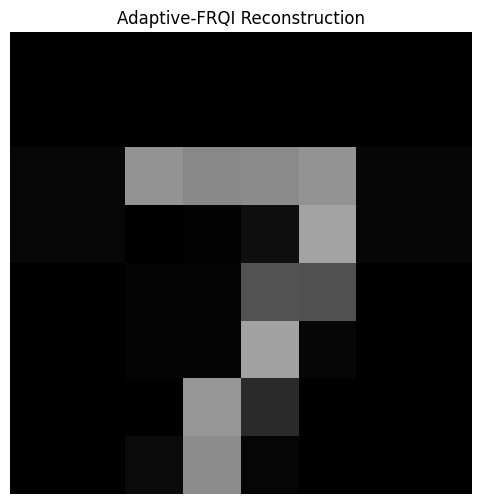

In [ ]:
plt.figure(figsize=(6, 6))

plt.imshow(
    adaptive_reconstructed,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title(
    "Adaptive-FRQI Reconstruction"
)

plt.axis("off")

plt.show()

In [ ]:
mse_adaptive_frqi = mse(
    image,
    adaptive_reconstructed
)

psnr_adaptive_frqi = psnr(
    image,
    adaptive_reconstructed,
    data_range=255
)

ssim_adaptive_frqi = ssim(
    image,
    adaptive_reconstructed,
    data_range=255
)

print("Adaptive-FRQI")
print("-------------")

print(
    "MSE  :",
    mse_adaptive_frqi
)

print(
    "PSNR :",
    psnr_adaptive_frqi,
    "dB"
)

print(
    "SSIM :",
    ssim_adaptive_frqi
)

Adaptive-FRQI
-------------
MSE  : 785.1862792968839
PSNR : 19.18107658933465 dB
SSIM : 0.8292778748856254


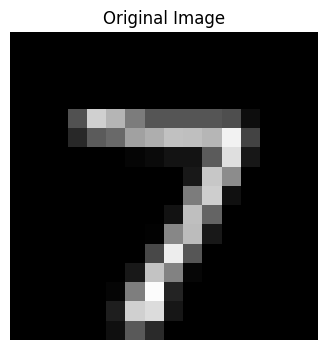

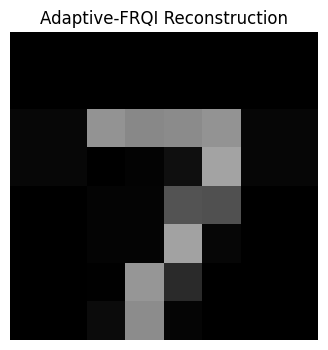

In [ ]:
plt.figure(figsize=(4, 4))

plt.imshow(
    image,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title(
    "Original Image"
)

plt.axis("off")

plt.show()

plt.figure(figsize=(4, 4))

plt.imshow(
    adaptive_reconstructed,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title(
    "Adaptive-FRQI Reconstruction"
)

plt.axis("off")

plt.show()

In [ ]:
classical_adaptive_reconstructed = np.zeros(
    (16, 16),
    dtype=np.float64
)

for element in adaptive_elements:

    x = element["x"]
    y = element["y"]
    size = element["size"]

    intensity = element["intensity"]

    classical_adaptive_reconstructed[
        y:y+size,
        x:x+size
    ] = intensity

mse_classical = mse(
    image,
    classical_adaptive_reconstructed
)

psnr_classical = psnr(
    image,
    classical_adaptive_reconstructed,
    data_range=255
)

ssim_classical = ssim(
    image,
    classical_adaptive_reconstructed,
    data_range=255
)

print("Improved Classical Adaptive Patch Reconstruction")
print("------------------------------------------------")
print("MSE  :", mse_classical)
print("PSNR :", psnr_classical, "dB")
print("SSIM :", ssim_classical)

Improved Classical Adaptive Patch Reconstruction
------------------------------------------------
MSE  : 785.186279296875
PSNR : 19.1810765893347 dB
SSIM : 0.8292778700110641


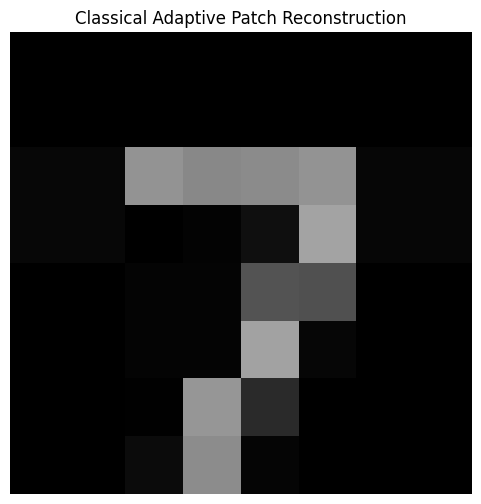

In [ ]:
plt.figure(figsize=(6, 6))

plt.imshow(
    classical_adaptive_reconstructed,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title(
    "Classical Adaptive Patch Reconstruction"
)

plt.axis("off")

plt.show()

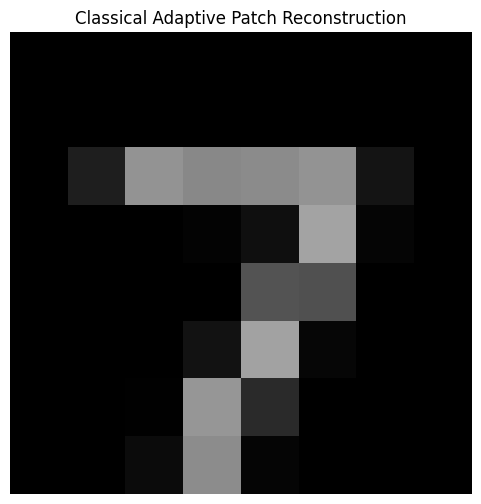

In [ ]:
# Classical Adaptive Patch Reconstruction

plt.figure(figsize=(6, 6))

plt.imshow(
    classical_adaptive_reconstructed,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("Classical Adaptive Patch Reconstruction")
plt.axis("off")

plt.show()